# Execution schedules and assignment likelihoods

Family 33. Liquidation trades reduce signed inventory to zero. Temporary impact scales with trade squared divided by interval length. Inventory risk is a preference and is reported separately from cash cost.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 33: liquidation schedules and generated binomial assignment data."""
import numpy as np
from convexity.math import execution

for aversion in (0., 2., 10.):
    result = execution.liquidate([10.], [.25]*4, spread=.01, impact=[[.5]], covariance=[[1.]], aversion=aversion)
    print('Inventory aversion:', aversion, 'trades:', result.trades[:, 0],
          'cash cost:', result.expected_cost, 'risk preference:', result.inventory_penalty)
rng = np.random.default_rng(3300)
x = np.column_stack([np.ones(1000), rng.normal(size=1000)])
true_beta = np.array([-.4, .8])
probability = 1/(1+np.exp(-x @ true_beta))
trials = np.full(len(x), 10)
fit = execution.fit_assignment(x, rng.binomial(trials, probability), trials)
print('True/fitted assignment coefficients:', true_beta, fit.coefficients)
print('Joint conditional assignment samples:', execution.assignment([3, 5], [.2, .4], draws=5, rng=rng))


Inventory aversion: 0.0 trades: [2.5 2.5 2.5 2.5] cash cost: 50.09999999994034 risk preference: 0.0
Inventory aversion: 2.0 trades: [4.10430839 2.63038549 1.81405896 1.45124717] cash cost: 58.42240681602536 risk preference: 23.76376098436083
Inventory aversion: 10.0 trades: [6.56372824 2.26838855 0.80853453 0.35934868] cash cost: 98.12194919786305 risk preference: 33.2526156531949
True/fitted assignment coefficients: [-0.4  0.8] [-0.42207622  0.81422041]
Joint conditional assignment samples: [[1 2]
 [0 0]
 [0 2]
 [1 1]
 [0 3]]


## Front-loading inventory and recovering assignment probabilities

Higher inventory aversion accelerates liquidation and generally raises expected cash cost. Assignment probabilities below are recovered from generated independent binomial counts under the declared logistic specification.

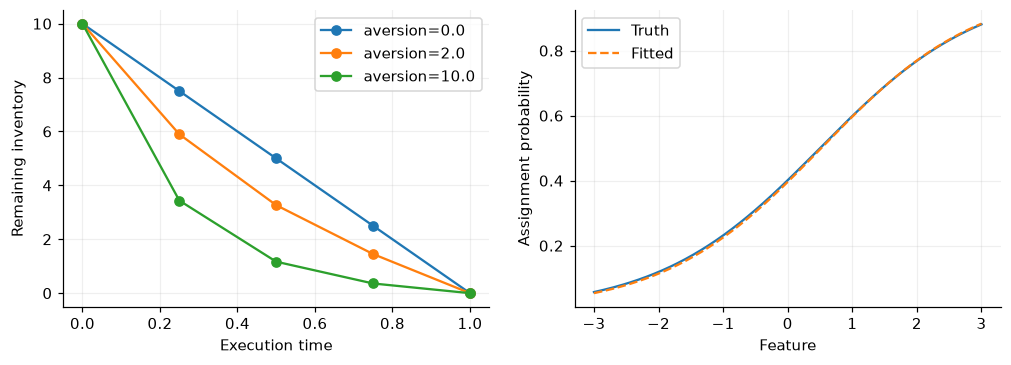

,Aversion,Cash cost,Risk preference
0,0.0,50.100000,0.000000
1,2.0,58.422407,23.763761
2,10.0,98.121949,33.252616


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
rows = []
for aversion in (0., 2., 10.):
    result = execution.liquidate([10.], [.25]*4, spread=.01, impact=[[.5]], covariance=[[1.]], aversion=aversion)
    axes[0].plot(np.linspace(0, 1, 5), result.inventory[:, 0], marker='o', label=f'aversion={aversion}')
    rows.append([aversion, result.expected_cost, result.inventory_penalty])
grid = np.linspace(-3, 3, 200)
features = np.column_stack([np.ones_like(grid), grid])
axes[1].plot(grid, 1/(1+np.exp(-features @ true_beta)), label='Truth')
axes[1].plot(grid, fit.probability(features), linestyle='--', label='Fitted')
axes[0].set(xlabel='Execution time', ylabel='Remaining inventory'); axes[0].legend()
axes[1].set(xlabel='Feature', ylabel='Assignment probability'); axes[1].legend(); plt.show()
display(pd.DataFrame(rows, columns=['Aversion', 'Cash cost', 'Risk preference']))

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.